# Validación de los modelos de churn y traducción a negocio

El notebook `01_eda.ipynb` entrena una regresión logística y un random forest y los evalúa sobre una única partición de prueba. Este notebook responde cuatro preguntas que ese análisis deja abiertas:

1. ¿Los modelos son mejores que no usar ningún modelo? (modelo base)
2. ¿Qué tan estables son las métricas? (validación cruzada estratificada)
3. ¿Qué pasa si se prioriza detectar más abandonos? (ajuste del umbral de decisión)
4. ¿Cuánto valdría usar el modelo en una campaña de retención? (traducción a negocio, con supuestos explícitos)

El conjunto de prueba se usa una sola vez, al final, y ninguna decisión (modelo o umbral) se toma mirándolo.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    confusion_matrix,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(exist_ok=True)

## 1. Datos y partición

Se usa la misma partición que en `01_eda.ipynb` (80/20, estratificada, semilla 42) para que los resultados sean comparables.

In [2]:
df = pd.read_csv("../data/telecom_churn.csv")
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"Entrenamiento: {len(X_train)} clientes, {y_train.mean():.1%} con churn")
print(f"Prueba:        {len(X_test)} clientes, {y_test.mean():.1%} con churn ({y_test.sum()} casos)")

Entrenamiento: 2666 clientes, 14.5% con churn
Prueba:        667 clientes, 14.5% con churn (97 casos)


## 2. Modelo base y validación cruzada

Se comparan tres modelos con validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento:

- **Modelo base**: predice siempre la clase mayoritaria ("nadie abandona"). Es el piso que cualquier modelo debe superar.
- **Regresión logística**, con las variables estandarizadas dentro de un `Pipeline`, de modo que el escalado se ajusta solo con los datos de entrenamiento de cada partición.
- **Random forest**, con los mismos hiperparámetros que en `01_eda.ipynb`.

Además de accuracy, precision, recall, F1 y ROC-AUC se reporta el **PR-AUC** (*average precision*), más informativo que el ROC-AUC cuando la clase positiva es minoritaria. El PR-AUC de un modelo sin información es igual a la proporción de churn (0,145).

In [3]:
models = {
    "Modelo base (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED, max_iter=1000)),
    "Random forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision",
}

rows = []
for name, model in models.items():
    with warnings.catch_warnings():
        # El modelo base nunca predice churn y sklearn avisa de que su precision no está definida.
        warnings.simplefilter("ignore")
        scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Modelo": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[metric] = f"{values.mean():.3f} ± {values.std():.3f}"
    rows.append(row)

cv_results = pd.DataFrame(rows).set_index("Modelo")
cv_results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,
Modelo base (clase mayoritaria),0.855 ± 0.001,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.145 ± 0.001
Regresión logística,0.858 ± 0.003,0.534 ± 0.026,0.184 ± 0.048,0.269 ± 0.053,0.814 ± 0.008,0.450 ± 0.025
Random forest,0.936 ± 0.004,0.895 ± 0.022,0.635 ± 0.036,0.742 ± 0.022,0.913 ± 0.009,0.819 ± 0.012


**Lectura.**

- El modelo base tiene un accuracy de 0,855 sin detectar ningún abandono. Por eso el accuracy no sirve para comparar modelos en este problema.
- La regresión logística (0,858) prácticamente no mejora el accuracy del modelo base y detecta solo el 18 % de los abandonos con el umbral por defecto. Sí ordena a los clientes mejor que el azar (ROC-AUC 0,814, PR-AUC 0,450).
- El random forest es claramente superior: recall de 0,635 con precision de 0,895 y PR-AUC de 0,819. La desviación entre particiones es pequeña (0,036 en recall), así que la ventaja no depende de una partición favorable.

## 3. Ajuste del umbral de decisión

Por defecto un cliente se marca como "en riesgo" si su probabilidad estimada es de 0,5 o más. En retención, no detectar a un cliente que se va suele costar más que contactar a uno que no se iba, así que tiene sentido bajar el umbral para ganar recall a cambio de precision.

El umbral se elige **sin usar el conjunto de prueba**: se obtienen predicciones fuera de partición (*out-of-fold*) sobre el entrenamiento y se toma el umbral que maximiza el **F2**, una métrica que pondera el recall cuatro veces más que la precision.

In [4]:
def best_f2_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    precision, recall = precision[:-1], recall[:-1]
    f2 = 5 * precision * recall / (4 * precision + recall + 1e-12)
    best = int(np.argmax(f2))
    return thresholds[best], precision[best], recall[best]


tunable = {name: model for name, model in models.items() if not isinstance(model, DummyClassifier)}
oof_probabilities = {}
thresholds = {}

for name, model in tunable.items():
    oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof_probabilities[name] = oof
    threshold, precision, recall = best_f2_threshold(y_train, oof)
    thresholds[name] = threshold
    print(f"{name}: umbral = {threshold:.3f} (fuera de partición: precision {precision:.3f}, recall {recall:.3f})")

Regresión logística: umbral = 0.136 (fuera de partición: precision 0.343, recall 0.782)


Random forest: umbral = 0.149 (fuera de partición: precision 0.565, recall 0.863)


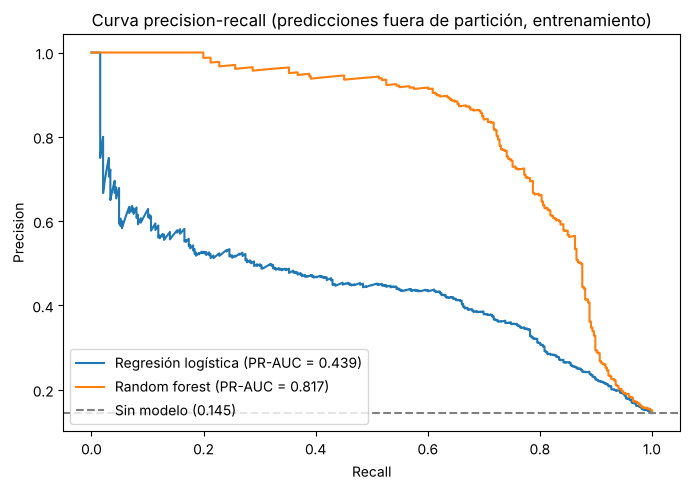

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, oof in oof_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_train, oof)
    ax.plot(recall, precision, label=f"{name} (PR-AUC = {average_precision_score(y_train, oof):.3f})")
ax.axhline(y_train.mean(), color="gray", linestyle="--", label=f"Sin modelo ({y_train.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curva precision-recall (predicciones fuera de partición, entrenamiento)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "precision_recall.png", dpi=150)
plt.show()

## 4. Evaluación final en el conjunto de prueba

Con los modelos y los umbrales ya fijados, se evalúa una sola vez sobre los 667 clientes de prueba (97 con churn).

In [6]:
fitted = {}
test_probabilities = {}
for name, model in tunable.items():
    fitted[name] = model.fit(X_train, y_train)
    test_probabilities[name] = fitted[name].predict_proba(X_test)[:, 1]

rows = []
predictions = {}
for name, probabilities in test_probabilities.items():
    for label, threshold in (("0,5 (por defecto)", 0.5), ("ajustado (F2)", thresholds[name])):
        predicted = (probabilities >= threshold).astype(int)
        predictions[(name, label)] = predicted
        tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
        rows.append(
            {
                "Modelo": name,
                "Umbral": label,
                "Valor del umbral": round(float(threshold), 3),
                "Precision": round(precision_score(y_test, predicted), 3),
                "Recall": round(recall_score(y_test, predicted), 3),
                "F2": round(fbeta_score(y_test, predicted, beta=2), 3),
                "Abandonos detectados": int(tp),
                "Abandonos no detectados": int(fn),
                "Falsas alarmas": int(fp),
                "Clientes contactados": int(tp + fp),
            }
        )

test_results = pd.DataFrame(rows).set_index(["Modelo", "Umbral"])
test_results

Valor del umbral  Precision  Recall  \
Modelo              Umbral                                                   
Regresión logística 0,5 (por defecto)             0.500      0.526   0.206   
                    ajustado (F2)                 0.136      0.326   0.773   
Random forest       0,5 (por defecto)             0.500      0.822   0.619   
                    ajustado (F2)                 0.149      0.458   0.794   

                                          F2  Abandonos detectados  \
Modelo              Umbral                                           
Regresión logística 0,5 (por defecto)  0.235                    20   
                    ajustado (F2)      0.607                    75   
Random forest       0,5 (por defecto)  0.651                    60   
                    ajustado (F2)      0.692                    77   

                                       Abandonos no detectados  \
Modelo              Umbral                                       
Regresión logística 0,5 (por defecto)                       77   
                    ajustado (F2)                           22   
Random forest       0,5 (por defecto)                       37   
                    ajustado (F2)                           20   

                                       Falsas alarmas  Clientes contactados  
Modelo              Umbral                                                   
Regresión logística 0,5 (por defecto)              18                    38  
                    ajustado (F2)                 155                   230  
Random forest       0,5 (por defecto)              13                    73  
                    ajustado (F2)                  91                   168

In [7]:
for name, probabilities in test_probabilities.items():
    print(
        f"{name}: ROC-AUC = {roc_auc_score(y_test, probabilities):.3f}, "
        f"PR-AUC = {average_precision_score(y_test, probabilities):.3f}"
    )

Regresión logística: ROC-AUC = 0.809, PR-AUC = 0.416
Random forest: ROC-AUC = 0.865, PR-AUC = 0.744


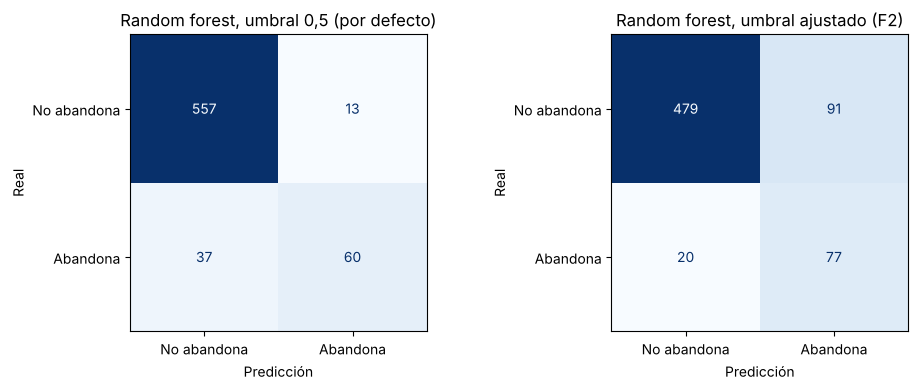

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, label in zip(axes, ("0,5 (por defecto)", "ajustado (F2)")):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[("Random forest", label)],
        display_labels=["No abandona", "Abandona"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"Random forest, umbral {label}")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "matriz_confusion_random_forest.png", dpi=150)
plt.show()

**Lectura.**

- Con el umbral por defecto, el random forest detecta 60 de los 97 abandonos (recall 0,619) con 13 falsas alarmas. Son las mismas cifras que en `01_eda.ipynb`.
- Con el umbral ajustado (0,149) detecta 77 de 97 (recall 0,794), pero las falsas alarmas suben de 13 a 91: para encontrar 17 abandonos más hay que contactar a 95 clientes adicionales.
- La regresión logística con umbral ajustado alcanza un recall parecido (0,773), pero con 155 falsas alarmas: a igual recall, el random forest es bastante más preciso.
- En prueba, el random forest obtiene un ROC-AUC de 0,865 y un PR-AUC de 0,744, por debajo de lo estimado en validación cruzada (0,913 y 0,819). Con solo 97 casos positivos, la estimación sobre una única partición de prueba es ruidosa; aun así, la diferencia indica que las cifras de validación cruzada son algo optimistas y que conviene informar ambas.

## 5. Traducción a negocio

¿Vale la pena la campaña de retención, y con qué umbral? Depende de cuánto vale retener a un cliente y de cuánto cuesta intentarlo. El dataset no trae esa información, así que se trabaja con **supuestos explícitos**, que no son datos de la empresa:

| Supuesto | Valor | Justificación |
|---|---|---|
| Valor de un cliente retenido | 12 × cargo mensual promedio | Se asume que un cliente retenido permanece un año más. El cargo mensual promedio sí sale de los datos. |
| Costo de contactar a un cliente | 1 cargo mensual promedio | Se asume una oferta equivalente a un mes gratis, que se entrega a todo cliente contactado, se fuera a ir o no. |
| Tasa de éxito de la oferta | 30 % | Se asume que 3 de cada 10 clientes que iban a abandonar se quedan si reciben la oferta. |

Los montos están en las unidades monetarias del dataset, que no declara moneda.

Beneficio neto de una campaña = (abandonos detectados × tasa de éxito × valor del cliente) − (clientes contactados × costo de contacto).

In [9]:
monthly_charge = df["MonthlyCharge"].mean()

ASSUMPTIONS = {
    "customer_value": 12 * monthly_charge,  # supuesto: el cliente retenido permanece 12 meses más
    "contact_cost": monthly_charge,         # supuesto: oferta equivalente a un mes gratis
    "success_rate": 0.30,                   # supuesto: 30 % de los abandonos contactados se quedan
}


def net_benefit(true_positives, contacted, success_rate, customer_value, contact_cost):
    return true_positives * success_rate * customer_value - contacted * contact_cost


def strategies(y_true):
    yield "Sin campaña", np.zeros(len(y_true), dtype=int)
    yield "Contactar a todos", np.ones(len(y_true), dtype=int)
    for (name, label), predicted in predictions.items():
        yield f"{name}, umbral {label}", predicted


rows = []
for strategy, predicted in strategies(y_test):
    tp = int(((predicted == 1) & (y_test == 1)).sum())
    contacted = int(predicted.sum())
    rows.append(
        {
            "Estrategia": strategy,
            "Clientes contactados": contacted,
            "Abandonos detectados": tp,
            "Beneficio neto": round(net_benefit(tp, contacted, **ASSUMPTIONS)),
        }
    )

print(f"Cargo mensual promedio: {monthly_charge:.2f}")
print(f"Valor supuesto de un cliente retenido: {ASSUMPTIONS['customer_value']:.2f}")
business = pd.DataFrame(rows).set_index("Estrategia")
business

Cargo mensual promedio: 56.31
Valor supuesto de un cliente retenido: 675.66


,Clientes contactados,Abandonos detectados,Beneficio neto
Estrategia,,,
Sin campaña,0,0,0
Contactar a todos,667,97,-17894
"Regresión logística, umbral 0,5 (por defecto)",38,20,1914
"Regresión logística, umbral ajustado (F2)",230,75,2252
"Random forest, umbral 0,5 (por defecto)",73,60,8052
"Random forest, umbral ajustado (F2)",168,77,6149


### Sensibilidad a la tasa de éxito

La tasa de éxito es el supuesto más incierto. La tabla repite el cálculo para tasas entre el 10 % y el 50 %.

In [10]:
rates = [0.10, 0.20, 0.30, 0.40, 0.50]
sensitivity = {}
for strategy, predicted in strategies(y_test):
    tp = int(((predicted == 1) & (y_test == 1)).sum())
    contacted = int(predicted.sum())
    sensitivity[strategy] = [
        round(net_benefit(tp, contacted, rate, ASSUMPTIONS["customer_value"], ASSUMPTIONS["contact_cost"]))
        for rate in rates
    ]

sensitivity = pd.DataFrame(sensitivity, index=[f"{rate:.0%}" for rate in rates]).T
sensitivity.columns.name = "Tasa de éxito"
sensitivity

Tasa de éxito,10%,20%,30%,40%,50%
Sin campaña,0,0,0,0,0
Contactar a todos,-31002,-24448,-17894,-11340,-4786
"Regresión logística, umbral 0,5 (por defecto)",-788,563,1914,3266,4617
"Regresión logística, umbral ajustado (F2)",-7883,-2815,2252,7320,12387
"Random forest, umbral 0,5 (por defecto)",-56,3998,8052,12106,16160
"Random forest, umbral ajustado (F2)",-4257,946,6149,11351,16554


In [11]:
break_even_precision = ASSUMPTIONS["contact_cost"] / (ASSUMPTIONS["success_rate"] * ASSUMPTIONS["customer_value"])
print(f"Precision mínima para que contactar a un cliente más sea rentable: {break_even_precision:.3f}")

Precision mínima para que contactar a un cliente más sea rentable: 0.278


**Lectura.**

- Bajo los supuestos base, usar el random forest con el umbral por defecto deja un beneficio neto de unas 8.050 unidades monetarias sobre los 667 clientes de prueba; sin modelo, contactar a todos pierde unas 17.900.
- **El umbral orientado a recall no es el más rentable con estos supuestos**: deja unas 6.150, menos que el umbral por defecto. Detecta 17 abandonos más, pero para lograrlo contacta a 95 clientes adicionales, y con una tasa de éxito del 30 % solo conviene contactar a un grupo en el que al menos el 27,8 % vaya a abandonar. En ese grupo adicional abandona el 17,9 % (17 de 95).
- La conclusión depende de la tasa de éxito: con un 50 % el umbral ajustado pasa a ser el más rentable, y con un 10 % ninguna estrategia es rentable y lo mejor es no hacer campaña.
- En todos los escenarios, la mejor opción con random forest supera a la mejor opción con regresión logística.

En resumen: maximizar el recall no es un objetivo de negocio por sí mismo. El umbral debería fijarse con el costo real de la oferta y su tasa de éxito, que habría que medir con una campaña piloto.

## 6. Limitaciones

- Los valores de negocio son supuestos, no datos de la empresa. El orden entre estrategias cambia según la tasa de éxito y el costo de la oferta.
- El conjunto de prueba tiene 97 abandonos; las métricas sobre él tienen un margen de error amplio. La validación cruzada da una estimación más estable, pero resultó algo optimista frente a la prueba.
- No se ajustaron hiperparámetros ni se probaron otros algoritmos; el objetivo de este notebook es validar correctamente los dos modelos existentes.
- No se calibraron las probabilidades. El umbral ajustado solo es válido para este modelo entrenado de esta forma.
- El dataset no tiene fechas, así que no se puede comprobar si el modelo se sostiene sobre clientes de un periodo posterior, que es como se usaría en la práctica.